# Hồi quy tuyến tính với Phương trình chuẩn (Normal Equation)

Cho tập dữ liệu $\mathcal{D} = \{(x_n, t_n)\}_{n=1}^N$ với $x_n \in \mathbb{R}^D$ và đích liên tục $t_n \in \mathbb{R}$.
Áp dụng Bias Trick bằng cách bổ sung $x_0 = 1$, ta có Ma trận thiết kế $\Phi \in \mathbb{R}^{N \times (D+1)}$ và vector trọng số $w \in \mathbb{R}^{D+1}$.

Hàm mất mát bình phương tổng phần dư (Sum-of-Squares Error):
$$\mathcal{L}(w) = \frac{1}{2} ||\Phi w - t||_2^2 = \frac{1}{2} (w^T \Phi^T \Phi w - 2 t^T \Phi w + t^T t)$$

Đạo hàm theo $w$ và đặt bằng $0$:
$$\nabla_w \mathcal{L}(w) = \Phi^T \Phi w - \Phi^T t = 0 \implies w^* = (\Phi^T \Phi)^{-1} \Phi^T t = \Phi^{\dagger} t$$

In [1]:
import numpy as np

class LinearRegressionNormalEq:
    def __init__(self, fit_intercept: bool = True):
        self.fit_intercept = fit_intercept
        self.weights = None
        self.intercept = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y).reshape(-1, 1)
        
        if self.fit_intercept:
            Phi = np.hstack([np.ones((X.shape[0], 1), dtype=X.dtype), X])
        else:
            Phi = X

        # Nghiệm giải tích qua giả nghịch đảo Moore-Penrose
        w_optimal = np.linalg.pinv(Phi) @ y

        if self.fit_intercept:
            self.intercept = float(w_optimal[0, 0])
            self.weights = w_optimal[1:].flatten()
        else:
            self.intercept = 0.0
            self.weights = w_optimal.flatten()
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.asarray(X) @ self.weights + self.intercept

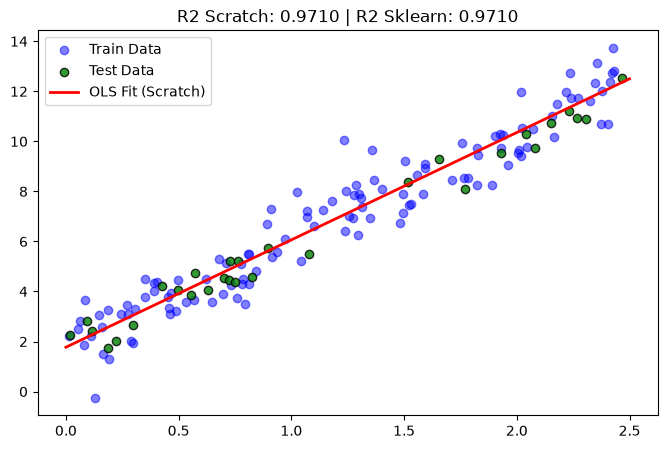

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from utils.metrics import r2_score, mean_squared_error
from utils.preprocessing import train_test_split

# Sinh dữ liệu
np.random.seed(42)
X = 2.5 * np.random.rand(150, 1)
y = 4.2 * X + 1.8 + np.random.randn(150, 1) * 0.8
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Scratch Model
t0 = time.time()
model_scratch = LinearRegressionNormalEq().fit(X_train, y_train)
t_scratch = (time.time() - t0) * 1000

# Train Sklearn Model
t0 = time.time()
model_sklearn = LinearRegression().fit(X_train, y_train)
t_sklearn = (time.time() - t0) * 1000

# Trực quan hóa
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.5, label='Train Data')
plt.scatter(X_test, y_test, color='green', alpha=0.8, edgecolors='k', label='Test Data')

X_line = np.linspace(0, 2.5, 100).reshape(-1, 1)
plt.plot(X_line, model_scratch.predict(X_line), color='red', linewidth=2, label='OLS Fit (Scratch)')
plt.legend()
plt.title(f"R2 Scratch: {r2_score(y_test, model_scratch.predict(X_test)):.4f} | R2 Sklearn: {model_sklearn.score(X_test, y_test):.4f}")
plt.show()